In [1]:
# EDINET APIからデータを取得するモジュール
import requests
import pandas as pd
import json
import time
from datetime import datetime, timedelta
import os
from dotenv import load_dotenv

In [ ]:
# EDINET APIのベースURL
BASE_URL = "https://disclosure.edinet-fsa.go.jp/api/v2"

In [3]:
# APIキーの読み込み
load_dotenv()
API_KEY = os.getenv("EDINET_API_KEY")
print(f"APIキー確認: {API_KEY[:5]}...")

APIキー確認: 6f3e7...


In [4]:
def get_documents_by_date(date: str) -> dict:
    url = f"{BASE_URL}/documents.json"
    params = {
        "date": date,
        "type": 2, # 有価証券報告書
        "Subscription-Key": API_KEY
    }
    response = requests.get(url, params=params)
    return response.json()

In [5]:
# テスト：直近の書類一覧を取得
test_date = "2024-01-15"
result = get_documents_by_date(test_date)
print(f"取得件数: {result.get('metadata', {}).get('resultset', {}).get('count', 0)}")
print(json.dumps(result['results'][0], ensure_ascii=False, indent=2))

取得件数: 437
{
  "seqNumber": 1,
  "docID": "S100SLX4",
  "edinetCode": "E36154",
  "secCode": null,
  "JCN": null,
  "filerName": "田畑　正吾",
  "fundCode": null,
  "ordinanceCode": "060",
  "formCode": "010002",
  "docTypeCode": "350",
  "periodStart": null,
  "periodEnd": null,
  "submitDateTime": "2024-01-15 09:00",
  "docDescription": "変更報告書",
  "issuerEdinetCode": "E34973",
  "subjectEdinetCode": null,
  "subsidiaryEdinetCode": null,
  "currentReportReason": null,
  "parentDocID": null,
  "opeDateTime": null,
  "withdrawalStatus": "0",
  "docInfoEditStatus": "0",
  "disclosureStatus": "0",
  "xbrlFlag": "1",
  "pdfFlag": "1",
  "attachDocFlag": "0",
  "englishDocFlag": "0",
  "csvFlag": "1",
  "legalStatus": "1"
}


In [6]:
# 有価証券報告書（docTypeCode: 120）のみに絞り込む関数
def filter_annual_reports(result: dict) -> list:
    """
    一般事業会社の有価証券報告書のみを抽出する
    docTypeCode: 120 = 有価証券報告書
    ordinanceCode: 010 = 一般事業会社
    """
    if not result.get('results'):
        return []
    return [
        doc for doc in result['results']
        if doc.get('docTypeCode') == '120'
        and doc.get('ordinanceCode') == '010'
    ]

In [7]:
# テスト
annual_reports = filter_annual_reports(result)
print(f"有価証券報告書の件数: {len(annual_reports)}")
if annual_reports:
    print(f"例: {annual_reports[0]['filerName']}")

有価証券報告書の件数: 1
例: 株式会社キタック


In [8]:
# 複数日付にわたって有価証券報告書を一括取得する
def get_annual_reports_bulk(start_date: str, end_date: str) -> pd.DataFrame:
    """
    指定期間の有価証券報告書一覧を取得する
    start_date, end_date: "YYYY-MM-DD" 形式
    """
    start = datetime.strptime(start_date, "%Y-%m-%d")
    end = datetime.strptime(end_date, "%Y-%m-%d")
    
    all_reports = []
    current = start
    
    while current <= end:
        date_str = current.strftime("%Y-%m-%d")
        try:
            result = get_documents_by_date(date_str)
            reports = filter_annual_reports(result)
            all_reports.extend(reports)
            print(f"{date_str}: {len(reports)}件取得")
        except Exception as e:
            print(f"{date_str}: エラー {e}")
        
        time.sleep(1)  # API負荷軽減のため1秒待機
        current += timedelta(days=1)
    
    return pd.DataFrame(all_reports)

In [9]:
# テスト：2024年6月の1週間分を取得(3月決算の会社が多いため)
df_reports = get_annual_reports_bulk("2024-06-24", "2024-06-30")
print(f"\n合計取得件数: {len(df_reports)}件")
print(df_reports[['filerName', 'docID', 'periodEnd']].head(10))

2024-06-24: 199件取得
2024-06-25: 265件取得
2024-06-26: 473件取得
2024-06-27: 703件取得
2024-06-28: 467件取得
2024-06-29: 0件取得
2024-06-30: 0件取得

合計取得件数: 2107件
          filerName     docID   periodEnd
0      日本空調サービス株式会社  S100TPNR  2024-03-31
1          今村証券株式会社  S100TNPR  2024-03-31
2        有馬冨士開発株式会社  S100TQCX  2024-03-31
3        三洋化成工業株式会社  S100TODJ  2024-03-31
4          株式会社大田花き  S100TQA4  2024-03-31
5  株式会社クリップコーポレーション  S100TQ70  2024-03-31
6          株式会社マンダム  S100TOZR  2024-03-31
7        遠州トラック株式会社  S100TPR6  2024-03-31
8          三信電気株式会社  S100TNW8  2024-03-31
9            日工株式会社  S100TO3E  2024-03-31


In [10]:
# 業種で絞り込む（建設業を確認）
# まずどんな会社名があるか確認
print("取得企業サンプル:")
print(df_reports['filerName'].head(20).to_string())
print(f"\n総企業数: {len(df_reports)}")

# データをCSVに保存（絶対パスで指定） ※生成AI利用(エラーの連続でエラー文を"Gemini"と投げ壁打ちした結果です)
import os
save_path = os.path.join(os.path.expanduser('~'), 'quest_1', 'data', 'annual_reports_list_202406.csv')
df_reports.to_csv(save_path, index=False, encoding='utf-8-sig')
print(f"\nCSV保存完了: {save_path}")

取得企業サンプル:
0             日本空調サービス株式会社
1                 今村証券株式会社
2               有馬冨士開発株式会社
3               三洋化成工業株式会社
4                 株式会社大田花き
5         株式会社クリップコーポレーション
6                 株式会社マンダム
7               遠州トラック株式会社
8                 三信電気株式会社
9                   日工株式会社
10                丸三証券株式会社
11                日進工具株式会社
12     株式会社　昭和システムエンジニアリング
13               北海道瓦斯株式会社
14                株式会社トーモク
15                ホクシン株式会社
16    福井コンピュータホールディングス株式会社
17               株式会社ニッカトー
18                 株式会社クレオ
19                ニッコー株式会社

総企業数: 2107

CSV保存完了: /Users/takeshiokada/quest_1/data/annual_reports_list_202406.csv


In [11]:
# 日揮HDが含まれているか確認
jgc = df_reports[df_reports['filerName'].str.contains('日揮', na=False)]
print(f"日揮関連企業:")
print(jgc[['filerName', 'docID', 'periodEnd']].to_string())

日揮関連企業:
           filerName     docID   periodEnd
1500  日揮ホールディングス株式会社  S100TVFX  2024-03-31


In [12]:
# 日揮HDの有価証券報告書をダウンロード
import zipfile
import io

def download_document(doc_id: str) -> bytes:
    """
    docIDを指定して書類をZIPでダウンロードする
    """
    url = f"{BASE_URL}/documents/{doc_id}"
    params = {
        "type": 1,  # XBRLファイル含むZIP
        "Subscription-Key": API_KEY
    }
    response = requests.get(url, params=params)
    return response.content

# 日揮HDの書類をダウンロード
jgc_doc_id = "S100TVFX"
print(f"ダウンロード開始: {jgc_doc_id}")
content = download_document(jgc_doc_id)
print(f"ダウンロード完了: {len(content)}バイト")

ダウンロード開始: S100TVFX
ダウンロード完了: 1172004バイト


In [13]:
# ZIPを展開してファイル一覧を確認
zip_file = zipfile.ZipFile(io.BytesIO(content))
file_list = zip_file.namelist()
print("ZIPの中身:")
for f in file_list:
    print(f)

ZIPの中身:
XBRL/PublicDoc/0000000_header_jpcrp030000-asr-001_E01575-000_2024-03-31_01_2024-06-27_ixbrl.htm
XBRL/PublicDoc/0101010_honbun_jpcrp030000-asr-001_E01575-000_2024-03-31_01_2024-06-27_ixbrl.htm
XBRL/PublicDoc/0102010_honbun_jpcrp030000-asr-001_E01575-000_2024-03-31_01_2024-06-27_ixbrl.htm
XBRL/PublicDoc/0103010_honbun_jpcrp030000-asr-001_E01575-000_2024-03-31_01_2024-06-27_ixbrl.htm
XBRL/PublicDoc/0104010_honbun_jpcrp030000-asr-001_E01575-000_2024-03-31_01_2024-06-27_ixbrl.htm
XBRL/PublicDoc/0105000_honbun_jpcrp030000-asr-001_E01575-000_2024-03-31_01_2024-06-27_ixbrl.htm
XBRL/PublicDoc/0105010_honbun_jpcrp030000-asr-001_E01575-000_2024-03-31_01_2024-06-27_ixbrl.htm
XBRL/PublicDoc/0105020_honbun_jpcrp030000-asr-001_E01575-000_2024-03-31_01_2024-06-27_ixbrl.htm
XBRL/PublicDoc/0105025_honbun_jpcrp030000-asr-001_E01575-000_2024-03-31_01_2024-06-27_ixbrl.htm
XBRL/PublicDoc/0105040_honbun_jpcrp030000-asr-001_E01575-000_2024-03-31_01_2024-06-27_ixbrl.htm
XBRL/PublicDoc/0105050_honbun_jp

In [14]:
# CSVファイルのみ抽出して確認
csv_files = [f for f in file_list if f.endswith('.csv')]
print("CSVファイル一覧:")
for f in csv_files:
    print(f)

CSVファイル一覧:


In [15]:
# HTMファイルのみ抽出して確認
htm_files = [f for f in file_list if f.endswith('.htm')]
print("HTMファイル一覧:")
for f in htm_files:
    print(f)

HTMファイル一覧:
XBRL/PublicDoc/0000000_header_jpcrp030000-asr-001_E01575-000_2024-03-31_01_2024-06-27_ixbrl.htm
XBRL/PublicDoc/0101010_honbun_jpcrp030000-asr-001_E01575-000_2024-03-31_01_2024-06-27_ixbrl.htm
XBRL/PublicDoc/0102010_honbun_jpcrp030000-asr-001_E01575-000_2024-03-31_01_2024-06-27_ixbrl.htm
XBRL/PublicDoc/0103010_honbun_jpcrp030000-asr-001_E01575-000_2024-03-31_01_2024-06-27_ixbrl.htm
XBRL/PublicDoc/0104010_honbun_jpcrp030000-asr-001_E01575-000_2024-03-31_01_2024-06-27_ixbrl.htm
XBRL/PublicDoc/0105000_honbun_jpcrp030000-asr-001_E01575-000_2024-03-31_01_2024-06-27_ixbrl.htm
XBRL/PublicDoc/0105010_honbun_jpcrp030000-asr-001_E01575-000_2024-03-31_01_2024-06-27_ixbrl.htm
XBRL/PublicDoc/0105020_honbun_jpcrp030000-asr-001_E01575-000_2024-03-31_01_2024-06-27_ixbrl.htm
XBRL/PublicDoc/0105025_honbun_jpcrp030000-asr-001_E01575-000_2024-03-31_01_2024-06-27_ixbrl.htm
XBRL/PublicDoc/0105040_honbun_jpcrp030000-asr-001_E01575-000_2024-03-31_01_2024-06-27_ixbrl.htm
XBRL/PublicDoc/0105050_honbun

In [16]:
# 本文HTMファイルを読み込んで女性活躍指標を探す
from bs4 import BeautifulSoup

# 最初の本文ファイルを読み込む
honbun_files = [f for f in htm_files if 'honbun' in f]
print(f"本文ファイル数: {len(honbun_files)}")

# 最初のファイルを読み込む
with zip_file.open(honbun_files[0]) as f:
    soup = BeautifulSoup(f.read(), 'html.parser')
    text = soup.get_text()

# 女性活躍関連キーワードで検索
keywords = ['女性管理職', '育児休業', '賃金格差', '女性活躍']
for keyword in keywords:
    idx = text.find(keyword)
    if idx != -1:
        print(f"\n【{keyword}】")
        print(text[idx:idx+200])

本文ファイル数: 22

【育児休業】
育児休業取得率及び労働者の男女の賃金の差異











当事業年度



 

管理職に占める女性労働者の割合（％）（注）２、３、４

男性労働者の育児休業取得率（％）（注）５、６

労働者の男女の賃金の差異（％）（注）２、７



全労働者

正規雇用労働者

パート・有期労働者（注）８、９



当社

3.3

63

57.8

60.5

34.6



日揮グローバル㈱

1


In [17]:
# 女性活躍指標を数値として抽出する
def extract_diversity_metrics(zip_content: bytes, company_name: str) -> dict:
    """
    ZIPファイルから女性活躍指標を抽出する
    """
    zip_file = zipfile.ZipFile(io.BytesIO(zip_content))
    file_list = zip_file.namelist()
    honbun_files = [f for f in file_list if 'honbun' in f and f.endswith('.htm')]
    
    metrics = {
        'company_name': company_name,
        'female_manager_ratio': None,
        'male_childcare_leave_rate': None,
        'gender_wage_gap': None
    }
    
    for honbun_file in honbun_files:
        with zip_file.open(honbun_file) as f:
            soup = BeautifulSoup(f.read(), 'html.parser')
            
            tags = {
                'female_manager_ratio': ['RatioOfFemaleWorkersToCorporateOfficers',
                                        'RatioOfFemaleManagers'],
                'male_childcare_leave_rate': ['RateOfMaleWorkersOnChildcareLeave'],
                'gender_wage_gap': ['RatioOfWomenSalaryToMenSalary',
                                   'DifferenceOfWagesBetweenMaleAndFemale']
            }
            
            for metric, tag_names in tags.items():
                for tag_name in tag_names:
                    tag = soup.find(attrs={'name': lambda x: x and tag_name.lower() in x.lower()})
                    if tag and tag.get_text(strip=True):
                        try:
                            metrics[metric] = float(tag.get_text(strip=True).replace(',', ''))
                            break
                        except:
                            pass
    
    return metrics

# 日揮HDでテスト
jgc_metrics = extract_diversity_metrics(content, '日揮ホールディングス株式会社')
print("日揮HD 女性活躍指標:")
for k, v in jgc_metrics.items():
    print(f"  {k}: {v}")

日揮HD 女性活躍指標:
  company_name: 日揮ホールディングス株式会社
  female_manager_ratio: None
  male_childcare_leave_rate: None
  gender_wage_gap: None


In [18]:
# 上記の数値が取れていない結果を踏まえて #
# XBRLタグ名を実際に確認する
with zip_file.open(honbun_files[0]) as f:
    soup = BeautifulSoup(f.read(), 'html.parser')
    
# 女性・育児・賃金に関連するタグを全部抽出
keywords = ['female', 'Female', 'childcare', 'Childcare', 'wage', 'Wage', 'salary', 'Salary']
found_tags = set()

for tag in soup.find_all(True):
    tag_name = tag.get('name', '')
    if tag_name and any(k in tag_name for k in keywords):
        found_tags.add(tag_name)

print("関連タグ一覧:")
for t in sorted(found_tags):
    print(t)

関連タグ一覧:
jpcrp_cor:AllEmployeesCalculatedBasedOnProvisionsOfArticle714Item1OfOrdinanceForEnforcementOfActOnChildcareLeaveCaregiverLeaveAndOtherMeasuresForTheWelfareOfWorkersCaringForChildrenOrOtherFamilyMembersRatioOfMaleEmployeesTakingChildcareLeaveMetricsOfReportingCompany
jpcrp_cor:AllEmployeesDifferencesInWagesBetweenMaleAndFemaleEmployeesMetricsOfConsolidatedSubsidiaries
jpcrp_cor:AllEmployeesDifferencesInWagesBetweenMaleAndFemaleEmployeesMetricsOfReportingCompany
jpcrp_cor:AllEmployeesRatioOfMaleEmployeesTakingChildcareLeaveMetricsOfConsolidatedSubsidiaries
jpcrp_cor:AverageAnnualSalaryInformationAboutReportingCompanyInformationAboutEmployees
jpcrp_cor:NonRegularEmployeesDifferencesInWagesBetweenMaleAndFemaleEmployeesMetricsOfConsolidatedSubsidiaries
jpcrp_cor:NonRegularEmployeesDifferencesInWagesBetweenMaleAndFemaleEmployeesMetricsOfReportingCompany
jpcrp_cor:RatioOfFemaleEmployeesInManagerialPositionsMetricsOfConsolidatedSubsidiaries
jpcrp_cor:RatioOfFemaleEmployeesInManagerialP

In [19]:
# 正しいタグ名で女性活躍指標を抽出する
def extract_diversity_metrics_v2(zip_content: bytes, company_name: str) -> dict:
    """
    正しいXBRLタグ名で女性活躍指標を抽出する
    """
    zip_file = zipfile.ZipFile(io.BytesIO(zip_content))
    file_list = zip_file.namelist()
    honbun_files = [f for f in file_list if 'honbun' in f and f.endswith('.htm')]
    
    metrics = {
        'company_name': company_name,
        'female_manager_ratio': None,       # 女性管理職比率
        'male_childcare_leave_rate': None,  # 男性育児休業取得率
        'gender_wage_gap': None             # 男女賃金格差（全労働者）
    }
    
    # 対応するタグ名
    tag_map = {
    'female_manager_ratio': 'jpcrp_cor:RatioOfFemaleEmployeesInManagerialPositionsMetricsOfReportingCompany',
    'male_childcare_leave_rate': 'jpcrp_cor:AllEmployeesCalculatedBasedOnProvisionsOfArticle714Item1OfOrdinanceForEnforcementOfActOnChildcareLeaveCaregiverLeaveAndOtherMeasuresForTheWelfareOfWorkersCaringForChildrenOrOtherFamilyMembersRatioOfMaleEmployeesTakingChildcareLeaveMetricsOfReportingCompany',
    'gender_wage_gap': 'jpcrp_cor:AllEmployeesDifferencesInWagesBetweenMaleAndFemaleEmployeesMetricsOfReportingCompany'
    }
    
    for honbun_file in honbun_files:
        with zip_file.open(honbun_file) as f:
            soup = BeautifulSoup(f.read(), 'html.parser')
            
            for metric, tag_name in tag_map.items():
                if metrics[metric] is not None:
                    continue
                tag = soup.find(attrs={'name': tag_name})
                if tag and tag.get_text(strip=True):
                    try:
                        metrics[metric] = float(tag.get_text(strip=True).replace(',', ''))
                    except:
                        pass
    
    return metrics

# 日揮HDでテスト
jgc_metrics = extract_diversity_metrics_v2(content, '日揮ホールディングス株式会社')
print("日揮HD 女性活躍指標:")
for k, v in jgc_metrics.items():
    print(f"  {k}: {v}")

日揮HD 女性活躍指標:
  company_name: 日揮ホールディングス株式会社
  female_manager_ratio: 3.3
  male_childcare_leave_rate: 63.0
  gender_wage_gap: 57.8


この数字の意味
- 女性管理職比率3.3%は非常に低い
- 男性育児休業取得率63%は比較的高め
- 男女賃金格差57.8%は女性の賃金が男性の約58%ということ

In [20]:
# ↑タグ名調査（試行錯誤） # ※生成AI利用(プロンプト：male_childcare_leave_rateがNoneがです。正しいタグ名を調べて下さい等)
# 育児休業関連のタグを全部確認する
with zip_file.open(honbun_files[0]) as f:
    soup = BeautifulSoup(f.read(), 'html.parser')

childcare_tags = {}
for tag in soup.find_all(True):
    tag_name = tag.get('name', '')
    if tag_name and 'childcare' in tag_name.lower() or (tag_name and 'childcare' in tag_name):
        childcare_tags[tag_name] = tag.get_text(strip=True)

print("育児休業関連タグと値:")
for k, v in childcare_tags.items():
    print(f"  {k}: {v}")

育児休業関連タグと値:
  jpcrp_cor:AllEmployeesCalculatedBasedOnProvisionsOfArticle714Item1OfOrdinanceForEnforcementOfActOnChildcareLeaveCaregiverLeaveAndOtherMeasuresForTheWelfareOfWorkersCaringForChildrenOrOtherFamilyMembersRatioOfMaleEmployeesTakingChildcareLeaveMetricsOfReportingCompany: 63
  jpcrp_cor:AllEmployeesRatioOfMaleEmployeesTakingChildcareLeaveMetricsOfConsolidatedSubsidiaries: 100


In [21]:
# EDINETコードリストから業種情報を取得する
# EDINETが提供している企業情報CSVをダウンロード
edinet_company_url = "https://disclosure.edinet-fsa.go.jp/E01EW/BLMainController.jsp?uji.verb=W1E62071CsvDownload&uji.bean=ee.W1E62071.W1E62071Bean&TID=W1E62071&PID=W1E62071&SESSIONKEY=&lgKbn=2&dflg=0&iflg=0&dispKbn=1"

response = requests.get(edinet_company_url)
print(f"ステータスコード: {response.status_code}")
print(f"コンテンツサイズ: {len(response.content)}バイト")

ステータスコード: 200
コンテンツサイズ: 7740バイト


ファイルサイズが小さすぎる。（7740バイト）CSVではなくHTMLが返ってきている可能性がある。

In [22]:
# EDINETコードリストを公式サイトから取得する(だめだった)↓
# EDINETコードリストを読み込む(EDINETコードリストからCSVを直接DL後dataに追加)
import os

edinet_code_path = os.path.join(os.path.expanduser('~'), 'quest_1', 'data', 'EdinetcodeDlInfo.csv')

# エンコーディングを指定して読み込む
df_companies = pd.read_csv(edinet_code_path, encoding='cp932', header=1)
print(f"企業数: {len(df_companies)}")
print(f"カラム: {df_companies.columns.tolist()}")
print(df_companies.head(3))

企業数: 11245
カラム: ['ＥＤＩＮＥＴコード', '提出者種別', '上場区分', '連結の有無', '資本金', '決算日', '提出者名', '提出者名（英字）', '提出者名（ヨミ）', '所在地', '提出者業種', '証券コード', '提出者法人番号']
  ＥＤＩＮＥＴコード    提出者種別 上場区分 連結の有無      資本金    決算日            提出者名  \
0    E00004  内国法人・組合   上場     有   1491.0  5月31日       カネコ種苗株式会社   
1    E00006  内国法人・組合   上場     有  13500.0  5月31日     株式会社　サカタのタネ   
2    E00007  内国法人・組合   上場     有    100.0  3月31日  ユキグニファクトリー株式会社   

                    提出者名（英字）            提出者名（ヨミ）              所在地   提出者業種  \
0     KANEKO SEEDS CO., LTD.    カネコシュビョウカブシキガイシャ  前橋市古市町一丁目５０番地１２  水産・農林業   
1    SAKATA SEED CORPORATION     カブシキガイシャ　サカタノタネ   横浜市都筑区仲町台２－７－１  水産・農林業   
2  YUKIGUNI FACTORY CO.,LTD.  ユニグニファクトリーカブシキガイシャ       南魚沼市余川８９番地  水産・農林業   

   証券コード       提出者法人番号  
0  13760  5.070001e+12  
1  13770  6.020001e+12  
2  13750  1.010001e+12  


In [23]:
# 業種一覧を確認する
print("業種一覧:")
print(df_companies['提出者業種'].value_counts().to_string())

業種一覧:
提出者業種
個人（組合発行者を除く）                 3100
内国法人・組合（有価証券報告書等の提出義務者以外）    2239
サービス業                         818
情報・通信業                        732
外国法人・組合（有価証券報告書等の提出義務者以外）     647
小売業                           412
卸売業                           378
電気機器                          279
機械                            248
化学                            235
建設業                           199
不動産業                          191
外国法人・組合                       174
食料品                           147
その他製品                         141
銀行業                           127
陸運業                           108
個人（非居住者）（組合発行者を除く）            107
金属製品                          101
輸送用機器                          99
医薬品                            96
その他金融業                         81
ガラス・土石製品                       67
精密機器                           58
証券、商品先物取引業                     58
繊維製品                           56
倉庫・運輸関連                        54
鉄鋼                             50
非鉄金属                           37
外国

In [24]:
# 建設業に絞り込む
df_construction = df_companies[df_companies['提出者業種'] == '建設業']
print(f"建設業企業数: {len(df_construction)}")
print(df_construction[['ＥＤＩＮＥＴコード', '提出者名', '提出者業種']].head(10).to_string())

建設業企業数: 199
   ＥＤＩＮＥＴコード         提出者名 提出者業種
6     E00011     住友林業株式会社   建設業
27    E00048  大和ハウス工業株式会社   建設業
28    E00049    株式会社ＮＩＰＰＯ   建設業
30    E00051   前田建設工業株式会社   建設業
31    E00052     大成建設株式会社   建設業
32    E00053     清水建設株式会社   建設業
33    E00055      株式会社大林組   建設業
34    E00056     株式会社　熊谷組   建設業
36    E00058     鹿島建設株式会社   建設業
37    E00059   日本国土開発株式会社   建設業


In [25]:
# この199社と先ほど取得した2107件の有価証券報告書を紐付け #
# 建設業のEDINETコード一覧を取得
construction_edinet_codes = df_construction['ＥＤＩＮＥＴコード'].tolist()

# 2107件の報告書リストと紐付け
df_construction_reports = df_reports[df_reports['edinetCode'].isin(construction_edinet_codes)]
print(f"建設業の有価証券報告書数: {len(df_construction_reports)}")
print(df_construction_reports[['filerName', 'docID', 'edinetCode']].to_string())

建設業の有価証券報告書数: 98
               filerName     docID edinetCode
41              株式会社守谷商会  S100TPIM     E00251
77           株式会社富士ピー・エス  S100TQJO     E00238
95             株式会社不動テトラ  S100TQ2Q     E00097
166           株式会社　高田工業所  S100TR3E     E00209
192             日特建設株式会社  S100TRAE     E00142
221            株式会社藤木工務店  S100TQFS     E00253
229             株式会社ソネック  S100TLYX     E00279
251             住友電設株式会社  S100TRI4     E00114
268             名工建設株式会社  S100TQL5     E00201
287             大東建託株式会社  S100TQFM     E00218
295          レイズネクスト株式会社  S100TRFN     E01577
300          日比谷総合設備株式会社  S100TS5K     E00168
332             大成温調株式会社  S100TR8D     E00233
404             五洋建設株式会社  S100TRIE     E00086
442     明豊ファシリティワークス株式会社  S100TSRM     E05377
488              株式会社中電工  S100TOEW     E00073
514             鹿島建設株式会社  S100TP3I     E00058
600          株式会社ミライト・ワン  S100TTGY     E24558
646             松尾建設株式会社  S100TQ7L     E00144
671            株式会社サンテック  S100TSVW     E00173
674             株

98社になっている理由：
1. 取得期間が2024年6月24日〜30日の1週間だけ

   ※3月決算以外の会社（12月決算など）はこの期間に提出していないため含まれていません。

2. 建設業199社全部が毎年同じ時期に提出するわけではない

In [26]:
# 2024年4月〜9月の半年間で有価証券報告書を再取得
df_reports_full = get_annual_reports_bulk("2024-04-01", "2024-09-30")
print(f"\n合計取得件数: {len(df_reports_full)}件")

# 建設業に絞り込む
df_construction_reports_full = df_reports_full[df_reports_full['edinetCode'].isin(construction_edinet_codes)]
print(f"建設業の有価証券報告書数: {len(df_construction_reports_full)}")

# CSVに保存
df_reports_full.to_csv(save_path.replace('annual_reports_list_202406.csv', 'annual_reports_list_2024.csv'), index=False, encoding='utf-8-sig')
print("CSV保存完了")

2024-04-01: 3件取得
2024-04-02: 1件取得
2024-04-03: 0件取得
2024-04-04: 1件取得
2024-04-05: 0件取得
2024-04-06: 0件取得
2024-04-07: 0件取得
2024-04-08: 0件取得
2024-04-09: 0件取得
2024-04-10: 0件取得
2024-04-11: 0件取得
2024-04-12: 0件取得
2024-04-13: 0件取得
2024-04-14: 0件取得
2024-04-15: 1件取得
2024-04-16: 1件取得
2024-04-17: 2件取得
2024-04-18: 0件取得
2024-04-19: 3件取得
2024-04-20: 0件取得
2024-04-21: 0件取得
2024-04-22: 3件取得
2024-04-23: 3件取得
2024-04-24: 7件取得
2024-04-25: 15件取得
2024-04-26: 39件取得
2024-04-27: 0件取得
2024-04-28: 0件取得
2024-04-29: 0件取得
2024-04-30: 29件取得
2024-05-01: 0件取得
2024-05-02: 1件取得
2024-05-03: 0件取得
2024-05-04: 0件取得
2024-05-05: 0件取得
2024-05-06: 0件取得
2024-05-07: 0件取得
2024-05-08: 0件取得
2024-05-09: 0件取得
2024-05-10: 0件取得
2024-05-11: 0件取得
2024-05-12: 0件取得
2024-05-13: 1件取得
2024-05-14: 0件取得
2024-05-15: 3件取得
2024-05-16: 1件取得
2024-05-17: 4件取得
2024-05-18: 0件取得
2024-05-19: 0件取得
2024-05-20: 2件取得
2024-05-21: 1件取得
2024-05-22: 6件取得
2024-05-23: 19件取得
2024-05-24: 36件取得
2024-05-25: 0件取得
2024-05-26: 0件取得
2024-05-27: 18件取得
2024-05-28: 14件取得
2024-05

一致しない理由：199社（EDINETコードリスト）→142社（2024年4月〜9月に提出した会社）

下記が考えられる
1. 決算期が特殊（1月・2月決算など）で期間外に提出
2. 有価証券報告書の提出が遅延
3. 上場廃止・合併などで提出なし

選択：142社で進める(建設業全体の傾向分析には十分な数だろう)

In [27]:
# 建設業142社の女性活躍指標を一括取得
all_metrics = []
total = len(df_construction_reports_full)

for i, (_, row) in enumerate(df_construction_reports_full.iterrows()):
    print(f"取得中 {i+1}/{total}: {row['filerName']}")
    try:
        zip_content = download_document(row['docID'])
        metrics = extract_diversity_metrics_v2(zip_content, row['filerName'])
        metrics['edinetCode'] = row['edinetCode']
        all_metrics.append(metrics)
        time.sleep(1)  # API負荷軽減
    except Exception as e:
        print(f"  エラー: {e}")
        all_metrics.append({
            'company_name': row['filerName'],
            'female_manager_ratio': None,
            'male_childcare_leave_rate': None,
            'gender_wage_gap': None,
            'edinetCode': row['edinetCode']
        })

df_metrics = pd.DataFrame(all_metrics)
print(f"\n取得完了: {len(df_metrics)}社")
print(df_metrics.head(10))

取得中 1/142: 太洋基礎工業株式会社
取得中 2/142: アップコン株式会社
取得中 3/142: 積水ハウス株式会社
取得中 4/142: ベステラ株式会社
取得中 5/142: 株式会社ダイセキ環境ソリューション
取得中 6/142: インターライフホールディングス株式会社
取得中 7/142: 株式会社ニットー
取得中 8/142: 株式会社ビーアールホールディングス
取得中 9/142: 株式会社ヤマト
取得中 10/142: 高砂熱学工業株式会社
取得中 11/142: 中外炉工業株式会社
取得中 12/142: 株式会社髙松コンストラクショングループ
取得中 13/142: 株式会社ＫＨＣ
取得中 14/142: 大成建設株式会社
取得中 15/142: 東光電気工事株式会社
取得中 16/142: 株式会社　森組
取得中 17/142: 明星工業株式会社
取得中 18/142: 南海辰村建設株式会社
取得中 19/142: 株式会社ピーエス三菱
取得中 20/142: 三機工業株式会社
取得中 21/142: 富士古河Ｅ＆Ｃ株式会社
取得中 22/142: 日本道路株式会社
取得中 23/142: 日本電設工業株式会社
取得中 24/142: 世紀東急工業株式会社
取得中 25/142: 新日本空調株式会社
取得中 26/142: 大末建設株式会社
取得中 27/142: 株式会社守谷商会
取得中 28/142: 株式会社富士ピー・エス
取得中 29/142: 株式会社不動テトラ
取得中 30/142: 株式会社　高田工業所
取得中 31/142: 日特建設株式会社
取得中 32/142: 株式会社藤木工務店
取得中 33/142: 株式会社ソネック
取得中 34/142: 住友電設株式会社
取得中 35/142: 名工建設株式会社
取得中 36/142: 大東建託株式会社
取得中 37/142: レイズネクスト株式会社
取得中 38/142: 日比谷総合設備株式会社
取得中 39/142: 大成温調株式会社
取得中 40/142: 五洋建設株式会社
取得中 41/142: 明豊ファシリティワークス株式会社
取得中 42/142: 株式会社中電工
取得中 43/142: 鹿島建設株式会社
取得中 44/142: 株式会社ミライト・ワン
取得中 

In [28]:
print(f"取得完了: {len(df_metrics)}社")
print(df_metrics.to_string())

取得完了: 142社
                company_name  female_manager_ratio  male_childcare_leave_rate  gender_wage_gap edinetCode
0                 太洋基礎工業株式会社                   NaN                        NaN              NaN     E00287
1                  アップコン株式会社                   NaN                        NaN              NaN     E36862
2                  積水ハウス株式会社                   NaN                        NaN              NaN     E00143
3                   ベステラ株式会社                   NaN                        NaN              NaN     E31731
4          株式会社ダイセキ環境ソリューション                   NaN                        NaN              NaN     E05444
5        インターライフホールディングス株式会社                   NaN                        NaN              NaN     E24512
6                   株式会社ニットー                   NaN                        NaN              NaN     E05065
7          株式会社ビーアールホールディングス                   NaN                        NaN              NaN     E00312
8                    株式会社ヤマト       

In [29]:
# データの取得状況を確認
print("各指標の取得状況:")
print(f"女性管理職比率: {df_metrics['female_manager_ratio'].notna().sum()}社 / 142社")
print(f"男性育児休業取得率: {df_metrics['male_childcare_leave_rate'].notna().sum()}社 / 142社")
print(f"男女賃金格差: {df_metrics['gender_wage_gap'].notna().sum()}社 / 142社")

print("\n基本統計:")
print(df_metrics[['female_manager_ratio', 'male_childcare_leave_rate', 'gender_wage_gap']].describe())

各指標の取得状況:
女性管理職比率: 106社 / 142社
男性育児休業取得率: 63社 / 142社
男女賃金格差: 107社 / 142社

基本統計:
       female_manager_ratio  male_childcare_leave_rate  gender_wage_gap
count            106.000000                  63.000000       107.000000
mean               3.286132                  46.659683        62.435794
std                4.242056                  29.274814         7.176034
min                0.000000                   0.000000        42.800000
25%                1.150000                  22.050000        57.800000
50%                2.700000                  46.000000        61.700000
75%                3.975000                  65.400000        67.400000
max               35.000000                 101.700000        80.100000


基本統計量から考察
- 女性管理職比率の **最大値が35%** の会社もある
- 男女賃金格差は **最小42.8%** の会社も
- 日揮HDの賃金格差は業界平均より悪い

## 建設業界と日揮HDの比較（暫定）

| 指標 | 建設業平均 | 日揮HD | 評価 |
|---|---|---|---|
| 女性管理職比率 | 3.3% | 3.3% | 業界平均と同水準 |
| 男性育児休業取得率 | 46.7% | 63.0% | 業界平均より高い |
| 男女賃金格差 | 62.4% | 57.8% | 業界平均より低い |

※ 男女賃金格差は女性賃金÷男性賃金の比率。数値が低いほど格差が大きい。

In [30]:
# 建設業女性活躍指標をCSVに保存
metrics_path = os.path.join(os.path.expanduser('~'), 'quest_1', 'data', 'construction_diversity_metrics.csv')
df_metrics.to_csv(metrics_path, index=False, encoding='utf-8-sig')
print(f"CSV保存完了: {metrics_path}")

CSV保存完了: /Users/takeshiokada/quest_1/data/construction_diversity_metrics.csv


In [31]:
# 全業界の女性活躍指標を業界平均で集計する #
# まず3278件全社から業種情報を付与する 
df_reports_full_with_industry = df_reports_full.merge(
    df_companies[['ＥＤＩＮＥＴコード', '提出者業種']],
    left_on='edinetCode',
    right_on='ＥＤＩＮＥＴコード',
    how='left'
)

print(f"業種付与後の件数: {len(df_reports_full_with_industry)}")
print(df_reports_full_with_industry['提出者業種'].value_counts().head(20).to_string())

業種付与後の件数: 3278
提出者業種
サービス業       403
情報・通信業      371
小売業         282
卸売業         276
電気機器        203
機械          175
化学          164
建設業         142
銀行業         103
外国法人・組合     103
食料品         102
不動産業         96
陸運業          95
その他製品        84
輸送用機器        81
金属製品         76
医薬品          54
その他金融業       52
ガラス・土石製品     49
倉庫・運輸関連      47


In [32]:
# 全業界から各業種上位30社に絞って取得
df_industry_sample = df_reports_full_with_industry.groupby('提出者業種').head(30).reset_index(drop=True)

# 外国法人・個人は除外
exclude = ['外国法人・組合', '個人（組合発行者を除く）', '内国法人・組合（有価証券報告書等の提出義務者以外）']
df_industry_sample = df_industry_sample[~df_industry_sample['提出者業種'].isin(exclude)]

print(f"対象件数: {len(df_industry_sample)}")
print(df_industry_sample['提出者業種'].value_counts().to_string())

対象件数: 845
提出者業種
サービス業                        30
繊維製品                         30
鉄鋼                           30
証券、商品先物取引業                   30
陸運業                          30
精密機器                         30
輸送用機器                        30
ガラス・土石製品                     30
情報・通信業                       30
銀行業                          30
倉庫・運輸関連                      30
その他金融業                       30
金属製品                         30
その他製品                        30
化学                           30
医薬品                          30
建設業                          30
機械                           30
電気機器                         30
小売業                          30
不動産業                         30
卸売業                          30
食料品                          30
電気・ガス業                       29
非鉄金属                         29
保険業                          22
パルプ・紙                        21
ゴム製品                         14
海運業                          11
水産・農林業                       10
石油・石炭製品                 

## ⚠️ 初回のみ実行（以降は下のCSV読み込みセルを使うこととします）
※ 実行時間約30分のため

In [33]:
# 全業界845社の女性活躍指標を一括取得
# all_metrics_industry = []
# total = len(df_industry_sample)

# for i, (_, row) in enumerate(df_industry_sample.iterrows()):
#     print(f"取得中 {i+1}/{total}: {row['filerName']} ({row['提出者業種']})")
#     try:
#         zip_content = download_document(row['docID'])
#         metrics = extract_diversity_metrics_v2(zip_content, row['filerName'])
#         metrics['edinetCode'] = row['edinetCode']
#         metrics['industry'] = row['提出者業種']
#         all_metrics_industry.append(metrics)
#         time.sleep(0.5)
#     except Exception as e:
#         print(f"  エラー: {e}")
#         all_metrics_industry.append({
#             'company_name': row['filerName'],
#             'female_manager_ratio': None,
#             'male_childcare_leave_rate': None,
#             'gender_wage_gap': None,
#             'edinetCode': row['edinetCode'],
#             'industry': row['提出者業種']
#         })

# df_metrics_industry = pd.DataFrame(all_metrics_industry)
# print(f"\n取得完了: {len(df_metrics_industry)}社")

取得中 1/845: 株式会社日高カントリー倶楽部 (サービス業)
取得中 2/845: 株式会社Ｐｈｏｔｏｓｙｎｔｈ (情報・通信業)
取得中 3/845: 株式会社エル・ティー・エス (サービス業)
取得中 4/845: ピープル株式会社 (その他製品)
取得中 5/845: ダイドーグループホールディングス株式会社 (食料品)
取得中 6/845: 株式会社タカショー (卸売業)
取得中 7/845: 株式会社ＴＯＫＹＯ　ＢＡＳＥ (小売業)
取得中 8/845: 株式会社三井ハイテック (電気機器)
取得中 9/845: 備後観光開発株式会社 (サービス業)
取得中 10/845: 株式会社鎌倉新書 (サービス業)
取得中 11/845: 株式会社シーイーシー (情報・通信業)
取得中 12/845: 株式会社Ｍマート (情報・通信業)
取得中 13/845: 株式会社光・彩 (その他製品)
取得中 14/845: 株式会社石井表記 (機械)
取得中 15/845: 株式会社トーホー (卸売業)
取得中 16/845: 太洋基礎工業株式会社 (建設業)
取得中 17/845: サンバイオ株式会社 (医薬品)
取得中 18/845: 株式会社トラース・オン・プロダクト (電気機器)
取得中 19/845: 不二電機工業株式会社 (電気機器)
取得中 20/845: 株式会社福岡カンツリー倶楽部 (サービス業)
取得中 21/845: スバル興業株式会社 (サービス業)
取得中 22/845: 株式会社アルトナー (サービス業)
取得中 23/845: 株式会社エニグモ (情報・通信業)
取得中 24/845: 株式会社アピリッツ (情報・通信業)
取得中 25/845: 株式会社丹青社 (サービス業)
取得中 26/845: アップコン株式会社 (建設業)
取得中 27/845: 株式会社ジャストプランニング (情報・通信業)
取得中 28/845: 株式会社アマガサ (卸売業)
取得中 29/845: 株式会社ＡＣＣＥＳＳ (情報・通信業)
取得中 30/845: 株式会社　トリケミカル研究所 (化学)
取得中 31/845: 積水ハウス株式会社 (建設業)
取得中 32/845: 株式会社コーセーアールイー (不動産業)
取得中 33/845: 株式会社き

In [34]:
# 全業界指標をCSVに保存
# industry_metrics_path = os.path.join(os.path.expanduser('~'), 'quest_1', 'data', 'industry_diversity_metrics.csv')
# df_metrics_industry.to_csv(industry_metrics_path, index=False, encoding='utf-8-sig')
# print(f"CSV保存完了: {industry_metrics_path}")

CSV保存完了: /Users/takeshiokada/quest_1/data/industry_diversity_metrics.csv


In [41]:
# ============================================
# 2回目以降はここから読み込む（上のセルは実行不要）
# ============================================
df_metrics = pd.read_csv(
    os.path.join(os.path.expanduser('~'), 'quest_1', 'data', 'construction_diversity_metrics.csv')
)
df_metrics_industry = pd.read_csv(
    os.path.join(os.path.expanduser('~'), 'quest_1', 'data', 'industry_diversity_metrics.csv')
)
print("CSV読み込み完了")
print(f"建設業: {len(df_metrics)}社")
print(f"全業界: {len(df_metrics_industry)}社")

CSV読み込み完了
建設業: 142社
全業界: 845社


In [35]:
# 全業界データの取得状況確認
print("全業界データ取得状況:")
print(f"女性管理職比率: {df_metrics_industry['female_manager_ratio'].notna().sum()}社 / 845社")
print(f"男性育児休業取得率: {df_metrics_industry['male_childcare_leave_rate'].notna().sum()}社 / 845社")
print(f"男女賃金格差: {df_metrics_industry['gender_wage_gap'].notna().sum()}社 / 845社")

print("\n業界別女性管理職比率平均:")
industry_avg = df_metrics_industry.groupby('industry')['female_manager_ratio'].mean().sort_values()
print(industry_avg.to_string())

全業界データ取得状況:
女性管理職比率: 457社 / 845社
男性育児休業取得率: 307社 / 845社
男女賃金格差: 462社 / 845社

業界別女性管理職比率平均:
industry
鉄鋼                            2.699565
建設業                           3.000000
鉱業                            3.450000
金属製品                          3.600000
輸送用機器                         3.669630
パルプ・紙                         4.180000
ゴム製品                          4.270000
陸運業                           5.343750
機械                            5.394444
ガラス・土石製品                      5.505000
非鉄金属                          5.981818
水産・農林業                        6.088889
石油・石炭製品                       6.425000
海運業                           6.845000
電気・ガス業                        6.985000
電気機器                          7.701250
化学                            7.976190
倉庫・運輸関連                       8.038333
繊維製品                          8.047368
精密機器                          8.404167
不動産業                         10.300000
食料品                          10.552381
その他製品                        11.628571
卸売業

In [36]:
# 業界別3指標の平均を整理
industry_summary = df_metrics_industry.groupby('industry').agg(
    female_manager_ratio=('female_manager_ratio', 'mean'),
    male_childcare_leave_rate=('male_childcare_leave_rate', 'mean'),
    gender_wage_gap=('gender_wage_gap', 'mean'),
    company_count=('company_name', 'count')
).round(2).sort_values('female_manager_ratio')

print("業界別女性活躍指標まとめ:")
print(industry_summary.to_string())

業界別女性活躍指標まとめ:
                           female_manager_ratio  male_childcare_leave_rate  gender_wage_gap  company_count
industry                                                                                                  
鉄鋼                                         2.70                      62.24            73.55             30
建設業                                        3.00                      47.22            62.84             30
鉱業                                         3.45                      60.00            62.45              4
金属製品                                       3.60                      53.08            68.99             30
輸送用機器                                      3.67                      56.65            71.49             30
パルプ・紙                                      4.18                      58.85            66.12             21
ゴム製品                                       4.27                      44.44            67.45             14
陸運業                    

In [37]:
# NaNを除いた業界別ランキング
industry_ranking = industry_summary.dropna().sort_values('female_manager_ratio')

print("【女性管理職比率 業界ランキング（低い順）】")
print(industry_ranking[['female_manager_ratio', 'gender_wage_gap', 'male_childcare_leave_rate']].to_string())

# 建設業の順位
rank = list(industry_ranking.index).index('建設業') + 1
total = len(industry_ranking)
print(f"\n建設業の順位: {rank}位 / {total}業界中")

【女性管理職比率 業界ランキング（低い順）】
            female_manager_ratio  gender_wage_gap  male_childcare_leave_rate
industry                                                                    
鉄鋼                          2.70            73.55                      62.24
建設業                         3.00            62.84                      47.22
鉱業                          3.45            62.45                      60.00
金属製品                        3.60            68.99                      53.08
輸送用機器                       3.67            71.49                      56.65
パルプ・紙                       4.18            66.12                      58.85
ゴム製品                        4.27            67.45                      44.44
陸運業                         5.34            68.63                      55.61
機械                          5.39            68.79                      47.70
ガラス・土石製品                    5.51            70.87                      45.35
非鉄金属                        5.98            70.05    

全業界平均 >> 建設業平均(3.00%) ≒ 日揮HD(3.3%)

女性管理職比率と男女賃金格差の相関係数: 0.281


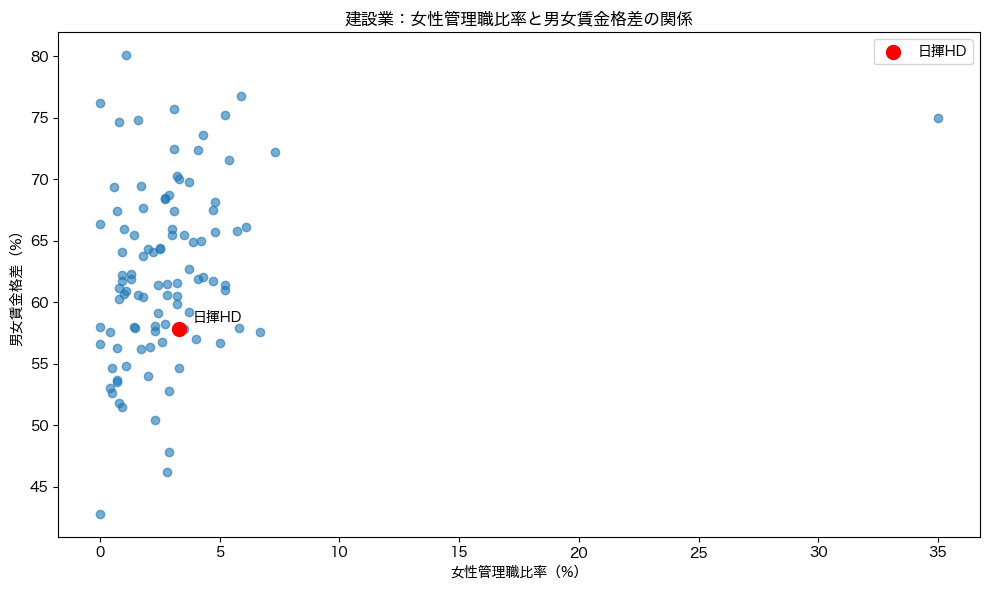

グラフ保存完了


In [38]:
# 仮説2の検証：女性管理職比率と男女賃金格差の相関
import matplotlib.pyplot as plt
import seaborn as sns

# 日本語フォント設定
plt.rcParams['font.family'] = 'Hiragino Sans'

# NaNを除いた建設業データ
df_construction_clean = df_metrics.dropna(subset=['female_manager_ratio', 'gender_wage_gap'])

# 相関係数
corr = df_construction_clean['female_manager_ratio'].corr(df_construction_clean['gender_wage_gap'])
print(f"女性管理職比率と男女賃金格差の相関係数: {corr:.3f}")

# 散布図
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(df_construction_clean['female_manager_ratio'], 
           df_construction_clean['gender_wage_gap'], 
           alpha=0.6)

# 日揮HDをハイライト
jgc = df_construction_clean[df_construction_clean['company_name'] == '日揮ホールディングス株式会社']
ax.scatter(jgc['female_manager_ratio'], jgc['gender_wage_gap'], 
           color='red', s=100, zorder=5, label='日揮HD') 
ax.annotate('日揮HD', (jgc['female_manager_ratio'].values[0], jgc['gender_wage_gap'].values[0]),
            textcoords="offset points", xytext=(10, 5))

ax.set_xlabel('女性管理職比率（%）')
ax.set_ylabel('男女賃金格差（%）')
ax.set_title('建設業：女性管理職比率と男女賃金格差の関係')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(os.path.expanduser('~'), 'quest_1', 'data', 'scatter_construction.png'), dpi=150)
plt.show()
print("グラフ保存完了")

相関係数0.281の意味：弱い正の相関

In [70]:
def extract_financial_data(zip_content: bytes, company_name: str) -> dict:
    zip_file = zipfile.ZipFile(io.BytesIO(zip_content))
    file_list = zip_file.namelist()
    honbun_files = [f for f in file_list if 'honbun' in f and f.endswith('.htm')]
    
    financials = {
        'company_name': company_name,
        'net_sales': None, # 売上高
        'net_profit': None # 当期純利益
    }
    
    tag_map = {
        'net_sales': 'jpcrp_cor:NetSalesSummaryOfBusinessResults',
        'net_profit': 'jpcrp_cor:ProfitLossAttributableToOwnersOfParentSummaryOfBusinessResults'
    }
    
    for honbun_file in honbun_files:
        with zip_file.open(honbun_file) as f:
            soup = BeautifulSoup(f.read(), 'html.parser')
            for metric, tag_name in tag_map.items():
                if financials[metric] is not None:
                    continue
                tags = soup.find_all(attrs={'name': tag_name})
                if tags:
                    for tag in tags:
                        text = tag.get_text(strip=True).replace(',', '')
                        try:
                            financials[metric] = float(text)
                            break
                        except:
                            pass
    
    return financials

In [71]:
jgc_financials = extract_financial_data(content, '日揮ホールディングス株式会社')
print("日揮HD 財務データ:")
for k, v in jgc_financials.items():
    print(f"  {k}: {v}")

日揮HD 財務データ:
  company_name: 日揮ホールディングス株式会社
  net_sales: 480809.0
  net_profit: 4117.0


In [72]:
all_financials = []
total = len(df_construction_reports_full)

for i, (_, row) in enumerate(df_construction_reports_full.iterrows()):
    print(f"取得中 {i+1}/{total}: {row['filerName']}")
    try:
        zip_content = download_document(row['docID'])
        financials = extract_financial_data(zip_content, row['filerName'])
        financials['edinetCode'] = row['edinetCode']
        all_financials.append(financials)
        time.sleep(0.5)
    except Exception as e:
        print(f"  エラー: {e}")

df_financials = pd.DataFrame(all_financials)
print(f"\n取得完了: {len(df_financials)}社")

# CSVに保存
financials_path = os.path.join(os.path.expanduser('~'), 'quest_1', 'data', 'construction_financials.csv')
df_financials.to_csv(financials_path, index=False, encoding='utf-8-sig')
print("CSV保存完了")

取得中 1/142: 太洋基礎工業株式会社
取得中 2/142: アップコン株式会社
取得中 3/142: 積水ハウス株式会社
取得中 4/142: ベステラ株式会社
取得中 5/142: 株式会社ダイセキ環境ソリューション
取得中 6/142: インターライフホールディングス株式会社
取得中 7/142: 株式会社ニットー
取得中 8/142: 株式会社ビーアールホールディングス
取得中 9/142: 株式会社ヤマト
取得中 10/142: 高砂熱学工業株式会社
取得中 11/142: 中外炉工業株式会社
取得中 12/142: 株式会社髙松コンストラクショングループ
取得中 13/142: 株式会社ＫＨＣ
取得中 14/142: 大成建設株式会社
取得中 15/142: 東光電気工事株式会社
取得中 16/142: 株式会社　森組
取得中 17/142: 明星工業株式会社
取得中 18/142: 南海辰村建設株式会社
取得中 19/142: 株式会社ピーエス三菱
取得中 20/142: 三機工業株式会社
取得中 21/142: 富士古河Ｅ＆Ｃ株式会社
取得中 22/142: 日本道路株式会社
取得中 23/142: 日本電設工業株式会社
取得中 24/142: 世紀東急工業株式会社
取得中 25/142: 新日本空調株式会社
取得中 26/142: 大末建設株式会社
取得中 27/142: 株式会社守谷商会
取得中 28/142: 株式会社富士ピー・エス
取得中 29/142: 株式会社不動テトラ
取得中 30/142: 株式会社　高田工業所
取得中 31/142: 日特建設株式会社
取得中 32/142: 株式会社藤木工務店
取得中 33/142: 株式会社ソネック
取得中 34/142: 住友電設株式会社
取得中 35/142: 名工建設株式会社
取得中 36/142: 大東建託株式会社
取得中 37/142: レイズネクスト株式会社
取得中 38/142: 日比谷総合設備株式会社
取得中 39/142: 大成温調株式会社
取得中 40/142: 五洋建設株式会社
取得中 41/142: 明豊ファシリティワークス株式会社
取得中 42/142: 株式会社中電工
取得中 43/142: 鹿島建設株式会社
取得中 44/142: 株式会社ミライト・ワン
取得中 

In [73]:
# 財務データの取得状況確認
print("財務データ取得状況:")
print(f"売上高: {df_financials['net_sales'].notna().sum()}社 / 142社")
print(f"純利益: {df_financials['net_profit'].notna().sum()}社 / 142社")

print("\n基本統計:")
print(df_financials[['net_sales', 'net_profit']].describe())

財務データ取得状況:
売上高: 135社 / 142社
純利益: 125社 / 142社

基本統計:
          net_sales    net_profit
count  1.350000e+02  1.250000e+02
mean   9.374893e+06  3.598109e+05
std    1.949779e+07  1.117875e+06
min    9.000000e+03  4.500000e+02
25%    8.976900e+04  3.537000e+03
50%    3.781350e+05  9.314000e+03
75%    8.337666e+06  1.593070e+05
max    1.460346e+08  1.065753e+07


In [74]:
# 女性活躍指標と財務データを結合
df_combined = df_metrics.merge(
    df_financials[['edinetCode', 'net_sales', 'net_profit']],
    on='edinetCode',
    how='inner'
)

print(f"結合後のデータ数: {len(df_combined)}社")
print(df_combined[['company_name', 'female_manager_ratio', 'gender_wage_gap', 'net_sales', 'net_profit']].head(10).to_string())

結合後のデータ数: 142社
          company_name  female_manager_ratio  gender_wage_gap   net_sales  net_profit
0           太洋基礎工業株式会社                   NaN              NaN  11853390.0         NaN
1            アップコン株式会社                   NaN              NaN    620144.0         NaN
2            積水ハウス株式会社                   NaN              NaN   2415186.0    141256.0
3             ベステラ株式会社                   NaN              NaN   3436154.0     59966.0
4    株式会社ダイセキ環境ソリューション                   NaN              NaN     14048.0       678.0
5  インターライフホールディングス株式会社                   NaN              NaN  19053081.0    108307.0
6             株式会社ニットー                   NaN              NaN   9066640.0    248736.0
7    株式会社ビーアールホールディングス                   NaN              NaN     34775.0      1348.0
8              株式会社ヤマト                   NaN              NaN  51464353.0   2398381.0
9           高砂熱学工業株式会社                   2.8             60.6    320893.0     13231.0


In [75]:
# 結合データをCSVに保存
combined_path = os.path.join(os.path.expanduser('~'), 'quest_1', 'data', 'construction_combined.csv')
df_combined.to_csv(combined_path, index=False, encoding='utf-8-sig')
print(f"CSV保存完了: {combined_path}")
print(f"データ数: {len(df_combined)}社")

CSV保存完了: /Users/takeshiokada/quest_1/data/construction_combined.csv
データ数: 142社
